# Phase 6Q-3 (Qwen3-8B): shallow KiL (policy graph as text in the prompt)

**Goal:** the first of the three KiL pipelines (RQ1, RQ2, H1). Same agent, model, settings and prose prompt as the baseline (05Q); the only change is that the policy graph is added to the prompt as text rules.

**Result (details in cell 16):** pass^1 0.140, pass^8 0.020. Far below the validator (Δpass^1 −0.240\*), no better than the baseline (−0.010, n.s.), and more illegal calls than the baseline (462 vs 339). H1 not supported on Qwen3-8B.

**Pipeline (example: cancel a flight):**

```
user input → [prompt = prose policy (wiki.md) + the whole policy graph as a rule checklist] → Qwen3-8B → action or reply
```

No validator, no extra calls, no training. The user simulator never sees the checklist.

**How the checklist is made:** `graph_text.py` (unchanged from Part 1) turns `airline_policy_graph.json` into plain rules: 5 global rules, then for each of the 7 actions what to ask first, the conditions that must all hold (with OR / AND groups and the rule ids), facts and the baggage table. It is added **after** the prose, as in Part 1 (07), so the agent loses nothing and the arm tests whether *adding the structured form* helps. The price: about 1,100 more words in every prompt, so the rules appear twice.

**The only difference from the validator (06Q):** here the rules reach the model as text and the model decides whether to follow them; in 06Q code checks every write call and blocks illegal ones. Neither checks anything before a call (that is semi-deep, 08Q).

**Spec check (brief → this notebook):**

| Brief says (quote) | This notebook | Same? |
|---|---|---|
| Shallow, "Input text": "Serialize the policy graph into the prompt as explicit rules, replacing or supplementing the prose policy" | `graph_text.full_text()` serializes the whole graph; added after `wiki.md` (supplementing) | yes |
| "Does structure beat prose when both are just context?" | shallow − baseline (05Q), paired over tasks (cell 11) | yes |
| "it should flatten the pass^k curve and reduce policy violations more than a hand-written runtime validator does" | shallow − validator (06Q), paired over tasks (cell 11), and all violation types (cell 12) | yes |
| "The headline result is the shape of the pass^k curve for k = 1 to 8" / "pass^k per domain, k = 1 to 8" | pass^k k = 1..8 with 95% CI, drop 1→8, curves of all three arms (cell 10) | yes |
| "illegal tool calls (a validator can catch these)" | 06G's checker replayed on a fresh database copy (cell 12) | yes |
| "dialogue-level violations (forbidden statements, skipped confirmations or explanations)" | skipped confirmation (G1), skipped explanation (G1: details not stated before the call; writes after one user message share one explanation), tool call + reply in one turn (G3), recommendation phrases (G2) (cell 12) | partly: automatic proxies; forbidden statements other than recommendations only by hand (cells 14–15) |
| "reasoning or argument errors" | writes rejected by the database, any tool error, malformed calls (cell 12) | partly: proxies; wrong-but-valid arguments only by hand |
| "Violation rate by turn position (early, middle, late)" | every violation type, per 100 dialogues and by third of the dialogue (cell 12) | yes |
| "Violations on tasks that still pass on final state" | for every violation type (cell 12) | yes |
| "Run each task at least 8 times with different simulator seeds" | 50 tasks × 8 trials; trial t gives seed t to every user-simulator call (`qwen_run.py`). Cell 7: Gemini accepts the seed, the same seed repeats a reply, another seed gives another reply. 2,892 seeded user calls logged | yes, with a caveat: Gemini calls its seed "best effort" |
| "Report means with confidence intervals" | 95% bootstrap CI for pass^k and for every paired difference | yes |
| "hand-check 30 failed trajectories to confirm whether errors come from the agent or the simulator" | 15 failed dialogues of this arm, fixed seed, labelled agent / simulator / benchmark / unclear with the buttons in cell 14b (result: 14 / 1 / 0 / 0, cell 15); 08Q and 09Q add 15 each, 45 in total, pooled in 10Q | yes, more than asked |
| Office hour: shallow, semi-deep and deep on Qwen | agent = Qwen3-8B | yes |

**Differences from 05Q / 06Q:** 05Q and 06Q ran before seeds were added, so their trials differ by sampling only. To compare all five systems under the same seeds, rerun 05Q and 06Q with `qwen_run.py` (about 6 h on an L4).

**Who plays which role:**

| Role | Model | Settings |
|---|---|---|
| Agent (the airline agent being tested) | **Qwen3-8B** on vLLM 0.34.0 | thinking off, temperature 0.0, hermes tool parser; prompt = wiki.md + graph checklist |
| Customer (the user simulator) | **Gemini** `gemini-3.1-flash-lite` | seed = trial number; temperature as set in `deep_run.py` (shown in cell 3) |

**Run first:** 04 (the graph), 06G (`policy_checker.py`, `violations.py`), `graph_text.py` (from Part 1), 05Q and 06Q (their results are the comparison lines). This notebook writes `qwen_run.py`. **Runtime:** L4 or larger; on an L4 the vLLM cell uses a 24k context and `--max-num-seqs 8`, and records both. **Time and cost (this run, L4):** 2.8 h for the full run, about $0.95 for the Gemini user simulator. The longer prompt leaves less room in the 24k context: if a dialogue hits the limit, cell 8 shows it as "not done". Run cell 8 once more; if it fails again, count it as a fail and do not keep rerunning (this run: none).

**Order:** 1 → 14 in order (not "Run all"). Then label the 15 dialogues with the buttons in cell 14b (saved to `results_qwen_shallow_handcheck/labels.xlsx`), run cell 15, and fill cell 16.

**Only re-analysing saved results?** Run cells 1, 2, 3, 9–15. No GPU server needed.

**Output:** `results_qwen_shallow/trial_1..8/` (dialogues, `calls.jsonl`, `seeds.log`), plus `results_qwen_shallow_config.json`, `_vllm.json`, `_passk.csv`, `_vs_validator.csv`, `_vs_base.csv`, `_violations.json`, `_consistency.json`, `_handcheck.json` and the folder `results_qwen_shallow_handcheck/` (15 dialogues + `labels.xlsx`) for 10Q. Safe to stop: finished tasks are skipped.

**Part 1 (Gemini) for reference:** shallow gave pass^1 0.520, pass^8 0.340 (same as its baseline), illegal calls 70 → 31, and stayed below the validator.

In [1]:
# Why: results and code live on Google Drive, so they survive when the Colab runtime resets.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Why: make sure every package the Qwen notebooks need is present, checked one by one. Colab images
# sometimes ship vLLM without litellm, so a single vLLM check lets cell 4 die on `import litellm`.
# Only missing packages get installed; vLLM takes a few minutes, the rest are quick.
import importlib, importlib.util, site, subprocess
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
PKGS = [("tau_bench", f"-e {ROOT}"), ("litellm", "litellm"), ("vllm", "vllm"),
        ("peft", "peft"), ("mcp", "mcp")]

def have(mod):
    importlib.invalidate_caches()
    try:
        site.main()            # pick up what pip just added to this running kernel
    except Exception:
        pass
    try:
        return importlib.util.find_spec(mod) is not None
    except Exception:
        return False

def pip_install(spec):
    r = subprocess.run(f"pip install -q {spec}", shell=True, capture_output=True, text=True, cwd=ROOT)
    return [l for l in (r.stdout + r.stderr).splitlines()
            if "error" in l.lower() and "protobuf" not in l.lower()]

rows, errors = [], []
for mod, spec in PKGS:
    if have(mod):
        rows.append({"package": mod, "action": "already there"})
        continue
    errors += pip_install(spec)
    if mod == "vllm":
        subprocess.run("pip uninstall -y -q torchao", shell=True, capture_output=True)  # clashes with vLLM
    rows.append({"package": mod, "action": "installed" if have(mod) else "❌ still missing"})

display(pd.DataFrame(rows).style.set_properties(**{"text-align": "left"}).hide(axis="index"))
if errors:
    print("\n".join(errors[-5:]))

package,action
tau_bench,installed
litellm,already there
vllm,installed
peft,already there
mcp,already there


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.


In [3]:
# Why: every arm must use the same frozen settings, or the comparison is not fair. The agent
# settings come from settings_deep.py and settings_gemini.py. The agent temperature is set here
# once and used by cells 5 and 6; an assert stops the run if it ever drifts from settings_gemini.
# The user simulator's temperature is not in the settings files, so the lines of deep_run.py that
# mention it are shown below (brief caveat: the simulator is an LLM and can be inconsistent).
# BASE_OUT (05Q) and VAL_OUT (06Q) are the comparison lines: read, never written to.
# The Gemini key comes from Colab Secrets and is never printed.
import os, sys, json, time, importlib, logging, warnings
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.insert(0, ROOT)
os.chdir(ROOT)
NEED = ["settings_gemini.py", "settings_deep.py", "deep_run.py", "policy_checker.py", "violations.py",
        "airline_policy_graph.json", "passk.py", "graph_text.py"]
missing = [f for f in NEED if not os.path.exists(f)]
assert not missing, f"missing {missing}: run 04 and 06G first; graph_text.py comes from Part 1 (07)"

importlib.invalidate_caches()
import settings_gemini, settings_deep, passk
importlib.reload(settings_gemini); importlib.reload(settings_deep)
from settings_gemini import (MODEL as USER_MODEL, ENV, N_TASKS, N_TRIALS,
                             TEMPERATURE, CONCURRENCY, PRICE_IN, PRICE_OUT)
from settings_deep import BASE_MODEL, SERVED_BASE, MAX_MODEL_LEN, GPU_MEM, AGENT_THINKING

AGENT_TEMP = 0.0                                    # one source of truth for cells 5 and 6
SEEDS = True        # simulator seed = trial number; set False only if cell 7 shows Gemini rejects a seed
assert TEMPERATURE == AGENT_TEMP, f"settings_gemini.TEMPERATURE is {TEMPERATURE}, expected {AGENT_TEMP}"
TEMP_LINES = [f"line {i}: {l.strip()[:90]}" for i, l in enumerate(open("deep_run.py"), 1) if "temperature" in l.lower()]
USER_TEMP = "see deep_run.py lines below"
ARM, OUT = "shallow", "results_qwen_shallow"
BASE_OUT, VAL_OUT = "results_qwen_base", "results_qwen_validator"
ARMS = [(f"qwen {ARM} (07Q)", OUT, "#00b894"),      # name, folder, color (H7); this arm first
        ("qwen validator (06Q)", VAL_OUT, "#f47230"),   # comparison only, never written to
        ("qwen base (05Q)", BASE_OUT, "#257de0")]       # comparison only, never written to

warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)
from google.colab import userdata
os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
os.environ["VLLM_BASE"] = "http://localhost:8000/v1"

def show(df):
    display(df.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

_TAB = {}
def tab_of(folder, reload=False):
    # read the saved dialogues off Drive once; cells 9-13 share the copy
    import passk
    if reload or folder not in _TAB:
        importlib.reload(passk)
        _TAB[folder] = passk.table(f"{ROOT}/{folder}")
    return _TAB[folder]

def has_checklist(r):
    # the saved dialogue starts with the system prompt; the checklist must be in it
    return any("Policy checklist" in str(m.get("content", "")) for m in (r.get("traj") or [])[:3] if isinstance(m, dict))

def n_seeded(folder):
    f = f"{folder}/seeds.log"
    return sum(1 for l in open(f) if l.strip()) if os.path.exists(f) else 0

found = lambda d: "(found)" if os.path.isdir(f"{ROOT}/{d}") else "⚠️ not found: run it first"
show(pd.DataFrame([
    {"setting": "agent model", "value": f"{BASE_MODEL} (served as {SERVED_BASE}), thinking {AGENT_THINKING}"},
    {"setting": "agent temperature", "value": str(AGENT_TEMP)},
    {"setting": "policy in prompt", "value": "wiki.md + the policy graph as a rule checklist (graph_text.py)"},
    {"setting": "validator", "value": "off"},
    {"setting": "user simulator", "value": f"{USER_MODEL} (Gemini, same as every arm)"},
    {"setting": "user temperature", "value": USER_TEMP},
    {"setting": "simulator seed", "value": "trial number 1..8, passed to every user-simulator call (qwen_run.py)" if SEEDS else "off (Gemini rejected the seed)"},
    {"setting": "env / tasks / trials", "value": f"{ENV} / {N_TASKS} / {N_TRIALS}"},
    {"setting": "concurrency", "value": str(CONCURRENCY)},
    {"setting": "output folder", "value": OUT},
    {"setting": "compared with", "value": f"{VAL_OUT} {found(VAL_OUT)}; {BASE_OUT} {found(BASE_OUT)}"},
] + [{"setting": "deep_run.py", "value": l} for l in TEMP_LINES or ["no line mentions temperature: provider default"]]))

setting,value
agent model,"Qwen/Qwen3-8B (served as qwen3-8b), thinking False"
agent temperature,0.0
policy in prompt,wiki.md + the policy graph as a rule checklist (graph_text.py)
validator,off
user simulator,"gemini-3.1-flash-lite (Gemini, same as every arm)"
user temperature,see deep_run.py lines below
simulator seed,"trial number 1..8, passed to every user-simulator call (qwen_run.py)"
env / tasks / trials,airline / 50 / 8
concurrency,4
output folder,results_qwen_shallow


In [4]:
# Why: write the runner and show what the agent gets. qwen_run.py (shared by every Qwen arm) gives
# each user-simulator call the trial's seed (brief: "different simulator seeds") and, for this arm,
# adds the graph checklist to the airline env's WIKI (the env reads it when it is built); then it runs
# deep_run.py unchanged. graph_text.py is the Part 1 file, unchanged, so the checklist is the same
# text Gemini got (Part 1: 1,107 words). Saved from a string, so there is no "Overwriting" noise.
import hashlib, importlib, graph_text as gt
importlib.reload(gt)
CODE = r'''# One runner for every Qwen arm (05Q-08Q). It does two things before running deep_run.py unchanged:
#  1. Simulator seed (brief: "Run each task at least 8 times with different simulator seeds"):
#     every call to the user simulator (Gemini) gets seed = SIM_SEED, the trial number 1..8.
#     Agent calls (Qwen on vLLM) are not touched. Each seeded call is counted in SEED_LOG.
#     If SIM_SEED is empty (Gemini does not accept a seed), nothing is changed.
#  2. Shallow KiL (07Q) when QWEN_SHALLOW=1: the whole policy graph, as text rules
#     (graph_text.py), is added to the agent's system prompt after the prose wiki.md.
import os
import runpy
import sys
import threading

import litellm

SEED = int(os.environ["SIM_SEED"]) if os.environ.get("SIM_SEED") else None
SEED_LOG = os.environ.get("SEED_LOG")
_lock = threading.Lock()


def _to_user_sim(kw):
    model = str(kw.get("model", ""))
    return kw.get("custom_llm_provider") == "gemini" or "gemini" in model.lower()


def _seeded(fn):
    if SEED is None or getattr(fn, "_seeded", False):
        return fn

    def wrap(*args, **kw):
        if _to_user_sim(kw):
            kw.setdefault("seed", SEED)
            if SEED_LOG:
                with _lock, open(SEED_LOG, "a") as f:
                    f.write(f"{SEED}\n")
        return fn(*args, **kw)

    wrap._seeded = True
    return wrap


# patch litellm first, so modules that later do "from litellm import completion" get the seeded one
litellm.completion = _seeded(litellm.completion)
import tau_bench.envs.user as user_mod  # noqa: E402

user_mod.completion = _seeded(user_mod.completion)

if os.environ.get("QWEN_SHALLOW") == "1":
    import graph_text as gt
    import tau_bench.envs.airline.env as airline_env   # the env reads WIKI when it is built
    airline_env.WIKI = airline_env.WIKI + "\n\n" + gt.full_text(gt.load())

here = os.path.dirname(os.path.abspath(__file__))
sys.argv[0] = os.path.join(here, "deep_run.py")
runpy.run_path(os.path.join(here, "deep_run.py"), run_name="__main__")
'''
old = open(f"{ROOT}/qwen_run.py").read() if os.path.exists(f"{ROOT}/qwen_run.py") else None
if old != CODE:
    open(f"{ROOT}/qwen_run.py", "w").write(CODE)
CHECKLIST = gt.full_text(gt.load())
show(pd.DataFrame([{"item": "qwen_run.py", "value": "unchanged" if old == CODE else ("updated" if old else "written")},
                   {"item": "checklist words", "value": f"{len(CHECKLIST.split())} (Part 1: 1,107)"},
                   {"item": "checklist id", "value": hashlib.md5(CHECKLIST.encode()).hexdigest()[:8]}]))
print(CHECKLIST[:1200], "\n...")

item,value
qwen_run.py,unchanged
checklist words,"1107 (Part 1: 1,107)"
checklist id,7cb6ea07


# Policy checklist (the same rules as the policy above, written as a graph)

## Global rules (every conversation)
- list the action details and get an explicit 'yes' from the user before the action [G1]. Applies to: book_reservation, update_reservation_flights, update_reservation_baggages, upgrade_cabin, update_reservation_passengers.
- give no information, knowledge or procedures not given by the user or the tools; no subjective recommendations or comments [G2].
- make one tool call at a time; never call a tool and reply to the user in the same turn [G3].
- deny user requests that are against this policy [G4].
- transfer to a human agent if and only if the request cannot be handled by any of the agent's actions [G5].

## Actions

### book_reservation (tool: book_reservation; from B1, B2, B3, B4, B5, D3)
Ask the user first: user_id [B1]; trip_type (one way or round trip) [B1]; origin [B1]; destination [B1]; first name, last name, date of birth of each passenger [B2]; payment methods [B

In [5]:
# Why: start Qwen3-8B on vLLM and test it. The GPU decides the settings: >= 40 GB (A100, G4, H100)
# uses the full 32k context; a 24 GB L4 only fits 24k (recorded in the config).
# max-num-seqs is capped at 2 x concurrency: the default (256) reserves warmup memory we never use,
# and on an L4 that leaves too little KV cache for 24k. The vLLM version is saved, since a newer
# vLLM can behave differently from the one an earlier arm used.
# Not needed to re-analyse saved results: for that, run cells 1, 2, 3, 8, 11, 12 only.
import subprocess, time, json, urllib.request, importlib.metadata, litellm
os.makedirs(f"{ROOT}/logs_qwen", exist_ok=True)
smi = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader,nounits",
                     shell=True, capture_output=True, text=True).stdout.strip()
assert ", " in smi, "no GPU found: Runtime > Change runtime type > pick a GPU"
GPU_NAME, gb = smi.splitlines()[0].split(", ")
GPU_GB = int(gb) / 1024
RUN_LEN, RUN_MEM = (MAX_MODEL_LEN, GPU_MEM) if GPU_GB >= 39 else (24576, "0.93")
MAX_SEQS = 2 * CONCURRENCY
VLLM_VER = importlib.metadata.version("vllm")
VLLM_LOG = f"{ROOT}/logs_qwen/vllm.log"
json.dump({"vllm": VLLM_VER, "max_num_seqs": MAX_SEQS, "gpu": GPU_NAME, "max_model_len": RUN_LEN},
          open(f"{ROOT}/{OUT}_vllm.json", "w"), indent=2)

def server_up():
    try:
        urllib.request.urlopen("http://localhost:8000/v1/models", timeout=5); return True
    except Exception:
        return False

t0 = time.time()
reused = server_up()
if not reused:
    cmd = (f"vllm serve {BASE_MODEL} --served-model-name {SERVED_BASE} --max-model-len {RUN_LEN} "
           f"--gpu-memory-utilization {RUN_MEM} --max-num-seqs {MAX_SEQS} "
           f"--enable-auto-tool-choice --tool-call-parser hermes --port 8000")
    with open(VLLM_LOG, "w") as lf:               # the server keeps its own handle; ours is closed
        server = subprocess.Popen(cmd, shell=True, stdout=lf, stderr=subprocess.STDOUT)
    while not server_up():
        if server.poll() is not None or time.time() - t0 > 1200:
            err = [l for l in open(VLLM_LOG).read().splitlines() if "error" in l.lower()][-3:]
            raise RuntimeError("vLLM did not start. Last errors in logs_qwen/vllm.log:\n" + "\n".join(err))
        time.sleep(10)

kw = dict(model=SERVED_BASE, custom_llm_provider="hosted_vllm", api_base=os.environ["VLLM_BASE"], api_key="none",
          temperature=AGENT_TEMP, extra_body={"chat_template_kwargs": {"enable_thinking": AGENT_THINKING}})
tools = [{"type": "function", "function": {"name": "get_reservation_details", "description": "Look up a reservation",
          "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}}, "required": ["reservation_id"]}}}]
msg = [{"role": "user", "content": "Look up reservation ABC123."}]
r1 = litellm.completion(**kw, tools=tools, messages=msg)
try:
    r2 = litellm.completion(**kw, tools=tools, tool_choice="none", messages=msg)
    none_ok = "✅" if not r2.choices[0].message.tool_calls else "⚠️ returned a call (ignored by kil_qwen.py)"
except Exception as e:
    none_ok = f"⚠️ not supported ({type(e).__name__}); kil_qwen.py falls back"
show(pd.DataFrame([
    {"check": "GPU", "result": f"{GPU_NAME}, {GPU_GB:.0f} GB"},
    {"check": "vLLM version", "result": VLLM_VER},
    {"check": "max length", "result": f"{RUN_LEN}" + ("" if RUN_LEN == MAX_MODEL_LEN else "  ⚠️ full setting is 32768: note in the report")},
    {"check": "max num seqs", "result": str(MAX_SEQS)},
    {"check": "vLLM", "result": "reused (already running)" if reused else f"started in {(time.time() - t0) / 60:.1f} min"},
    {"check": "tool call", "result": "✅" if r1.choices[0].message.tool_calls else "❌"},
    {"check": "text-only call (semi-deep needs it)", "result": none_ok}]))

check,result
GPU,"NVIDIA L4, 22 GB"
vLLM version,0.34.0
max length,24576 ⚠️ full setting is 32768: note in the report
max num seqs,8
vLLM,started in 4.7 min
tool call,✅
text-only call (semi-deep needs it),✅


In [6]:
# Why: one function runs this arm for 8 trials x 50 tasks, one folder per trial, with qwen_run.py
# (seed + checklist, then deep_run.py: agent -> Qwen on vLLM, user -> Gemini). Trial t uses
# simulator seed t, so every trial has a different seed and a rerun of a trial uses the same one
# (SEEDS in cell 3 turns seeds off, only if Gemini rejects them).
# Finished tasks are skipped, so a stopped run can simply be started again. The config is written
# only when a task really runs, so a rerun of a finished arm never overwrites its config.
import time, json, importlib, passk; importlib.reload(passk)
VALIDATOR = False

def run_arm(out, tasks=None, trials=None, arm=ARM):
    os.environ["DEEP_VALIDATOR"] = "1" if VALIDATOR else "0"
    os.environ["QWEN_SHALLOW"] = "1"
    config = {"agent": BASE_MODEL, "user": USER_MODEL, "arm": arm, "validator": VALIDATOR,
              "policy": "wiki.md + graph checklist (graph_text.full_text)",
              "checklist_id": hashlib.md5(CHECKLIST.encode()).hexdigest()[:8],
              "simulator_seed": "trial number (trial_1 -> 1 ... trial_8 -> 8)" if SEEDS
                                else "none: Gemini did not accept a seed (07Q cell 7)",
              "agent_temperature": AGENT_TEMP, "user_temperature": TEMP_LINES,
              "gpu": GPU_NAME, "max_model_len": RUN_LEN, "max_num_seqs": MAX_SEQS, "vllm": VLLM_VER}
    rows, wrote = [], False
    for trial in (trials or range(1, N_TRIALS + 1)):
        folder = f"{ROOT}/{out}/trial_{trial}"
        os.makedirs(folder, exist_ok=True)
        want = set(tasks if tasks is not None else range(N_TASKS))
        todo = sorted(want - passk.done_tasks(folder))
        if not todo:
            rows.append({"trial": trial, "ran": 0, "min": "-", "not done": 0, "note": "already done"})
            continue
        if not wrote:
            json.dump(config, open(f"{ROOT}/{out}_config.json", "w"), indent=2); wrote = True
        print(f"trial {trial}: running {len(todo)} tasks (simulator seed {trial if SEEDS else 'none'}) ...", flush=True)
        t0 = time.time()
        os.environ["SIM_SEED"] = str(trial) if SEEDS else ""
        os.environ["SEED_LOG"] = f"{folder}/seeds.log"
        os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
        os.environ["VALIDATOR_LOG"] = f"{folder}/blocks.jsonl"
        ids = " ".join(map(str, todo))
        log = f"{ROOT}/logs_qwen/{out}_trial_{trial}.log"
        !cd {ROOT} && python qwen_run.py --env {ENV} --agent-strategy tool-calling \
          --model {SERVED_BASE} --model-provider hosted_vllm \
          --user-model {USER_MODEL} --user-model-provider gemini \
          --user-strategy llm --num-trials 1 --temperature {AGENT_TEMP} \
          --task-ids {ids} --max-concurrency {CONCURRENCY} \
          --log-dir {folder} >> {log} 2>&1
        left = len(want - passk.done_tasks(folder))
        note = ""
        if left:
            bad = [l for l in open(log).read().splitlines() if "Error" in l or "Traceback" in l][-1:]
            note = bad[0][:80] if bad else f"see logs_qwen/{out}_trial_{trial}.log"
        rows.append({"trial": trial, "ran": len(todo), "min": f"{(time.time() - t0) / 60:.1f}",
                     "not done": left, "note": note})
    _TAB.pop(out, None)                           # results changed: drop the cached dialogues
    show(pd.DataFrame(rows))

In [7]:
# Why: before the full run, check the three things this arm depends on:
#  1. the Gemini API accepts a seed, and the same seed gives the same reply (Gemini calls this
#     "best effort"), while another seed may differ: 3 direct calls at the simulator's default settings
#  2. a 2-task run finishes with no API errors, every user-simulator call was seeded, and the
#     checklist really is in the agent's prompt (read back from the saved dialogues)
#  3. how long and how much the full run will take (the formula matched the real 05Q run)
import shutil, litellm
probe = [{"role": "system", "content": "You are a customer of an airline. Write one short, natural sentence "
                                      "asking to change your flight. Vary the wording."},
         {"role": "user", "content": "Hi! How can I help you today?"}]
def ask(seed):
    r = litellm.completion(model=USER_MODEL, custom_llm_provider="gemini", messages=probe, seed=seed)
    return r.choices[0].message.content.strip()
try:
    a1, a2, b1 = ask(1), ask(1), ask(2)
    seed_ok, same, diff = True, a1 == a2, a1 != b1
except Exception as e:
    seed_ok, same, diff, a1 = False, False, False, f"{type(e).__name__}: {str(e)[:150]}"
show(pd.DataFrame([{"Gemini accepts seed": "✅" if seed_ok else "❌", "seed 1 twice → same reply": "✅" if same else "⚠️ no",
                    "seed 2 → other reply": "yes" if diff else "no", "reply (seed 1)": a1[:90]}]))

SMOKE = f"{OUT}_smoke"
shutil.rmtree(f"{ROOT}/{SMOKE}", ignore_errors=True)
t0 = time.time()
run_arm(SMOKE, tasks=[0, 1], trials=[1])
sec = time.time() - t0
tab = tab_of(SMOKE, reload=True)
done = sum(len(v) for v in tab.values())
errs = sum(passk.is_error(r) for v in tab.values() for r in v.values())
inprompt = sum(has_checklist(r) for v in tab.values() for r in v.values())
seeded = n_seeded(f"{ROOT}/{SMOKE}/trial_1")
cl = f"{ROOT}/{SMOKE}/trial_1/calls.jsonl"
calls = [json.loads(l) for l in open(cl)] if os.path.exists(cl) else []
user_calls = sum(c["who"] == "user" for c in calls)
usd = sum(c["prompt"] * PRICE_IN + c["completion"] * PRICE_OUT for c in calls if c["who"] == "user") / 1e6
ok = done == 2 and errs == 0 and inprompt == done and (seeded > 0 if SEEDS else True)
show(pd.DataFrame([{"dialogues done": f"{done}/2", "API errors": errs, "checklist in prompt": f"{inprompt}/{done}",
                    "seeded user calls": f"{seeded} (user calls logged: {user_calls})",
                    "est. full run": f"{sec / max(done, 1) * N_TASKS * N_TRIALS / CONCURRENCY / 3600:.1f} h",
                    "est. Gemini cost": f"${usd / max(done, 1) * N_TASKS * N_TRIALS:.2f}",
                    "go on?": "✅ run the next cell" if ok else "❌ check the table and the log"}]))
if not seed_ok and SEEDS:
    print("Gemini does not accept a seed: every user-simulator call would fail. Set SEEDS = False in cell 3, "
          "run cells 3, 6 and 7 again, and write in the report that the simulator could not be seeded.")
if not same and seed_ok:
    print("Note: Gemini accepted the seed but gave two different replies for the same seed. Seeds are "
          "'best effort' on Gemini, so trials still differ by seed, but a rerun may not repeat a dialogue "
          "exactly. Write this in the report.")

Gemini accepts seed,seed 1 twice → same reply,seed 2 → other reply,reply (seed 1)
✅,✅,yes,I’d like to see if I can switch my flight to a different time tomorrow.


trial 1: running 2 tasks (simulator seed 1) ...


trial,ran,min,not done,note
1,2,3.6,0,


dialogues done,API errors,checklist in prompt,seeded user calls,est. full run,est. Gemini cost,go on?
2/2,0,2/2,18 (user calls logged: 18),3.0 h,$0.95,✅ run the next cell


In [8]:
# Why: the full run (8 trials x 50 tasks).
run_arm(OUT)

trial 1: running 49 tasks (simulator seed 1) ...
trial 2: running 50 tasks (simulator seed 2) ...
trial 3: running 50 tasks (simulator seed 3) ...
trial 4: running 50 tasks (simulator seed 4) ...
trial 5: running 50 tasks (simulator seed 5) ...
trial 6: running 50 tasks (simulator seed 6) ...
trial 7: running 50 tasks (simulator seed 7) ...
trial 8: running 50 tasks (simulator seed 8) ...


trial,ran,min,not done,note
1,49,18.8,0,
2,50,21.6,0,
3,50,21.2,0,
4,50,22.7,0,
5,50,20.2,0,
6,50,21.3,0,
7,50,22.3,0,
8,50,20.5,0,


In [9]:
# Why: see at a glance whether every trial finished, how many API errors there were (an error
# counts as a fail, so those tasks must be run again), that every dialogue had the checklist, and
# that the user simulator got the trial's seed.
tab = tab_of(OUT, reload=True)
show(pd.DataFrame([{"trial": t, "simulator seed": t if SEEDS else "none", "done": f"{len(tab.get(t, {}))}/{N_TASKS}",
                    "passed": sum(x["reward"] >= 1 - 1e-6 for x in tab.get(t, {}).values()),
                    "API errors": sum(passk.is_error(x) for x in tab.get(t, {}).values()),
                    "checklist in prompt": f"{sum(has_checklist(x) for x in tab.get(t, {}).values())}/{len(tab.get(t, {}))}",
                    "seeded user calls": n_seeded(f"{ROOT}/{OUT}/trial_{t}")}
                   for t in range(1, N_TRIALS + 1)]))

trial,simulator seed,done,passed,API errors,checklist in prompt,seeded user calls
1,1,50/50,7,0,50/50,377
2,2,50/50,8,0,50/50,401
3,3,50/50,5,0,50/50,366
4,4,50/50,10,0,50/50,349
5,5,50/50,6,0,50/50,357
6,6,50/50,6,0,50/50,360
7,7,50/50,7,0,50/50,340
8,8,50/50,7,0,50/50,342


arm,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8,95% CI k=1,drop 1→8
qwen shallow (07Q),0.140,0.056,0.032,0.023,0.021,0.020,0.020,0.020,"[0.08, 0.20]",86%
qwen validator (06Q),0.380,0.296,0.260,0.239,0.226,0.216,0.207,0.200,"[0.27, 0.49]",47%
qwen base (05Q),0.150,0.071,0.039,0.022,0.013,0.006,0.003,0.000,"[0.09, 0.22]",100%


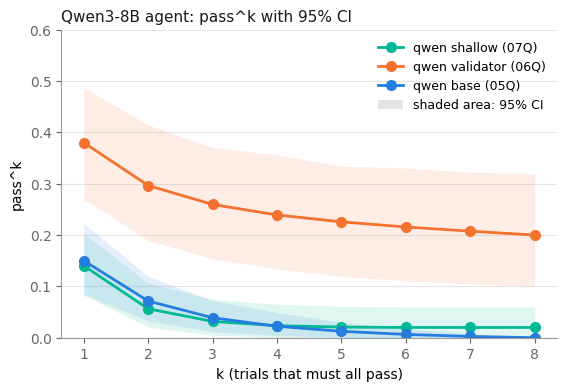

In [10]:
# Why: pass^k (k = 1..8) with 95% CI is the headline metric. The validator (06Q) and the baseline (05Q)
# are drawn in the same chart. ylim stays fixed at 0.6 so every Qwen notebook draws on the same axis (H7).
# Only this arm's csv is written; 05Q's and 06Q's files are never touched.
import csv, matplotlib.pyplot as plt
from matplotlib.patches import Patch
curves = {name: passk.curve(f"{ROOT}/{d}", N_TASKS)[1] for name, d, _ in ARMS}
show(pd.DataFrame([{"arm": n, **{f"k={r['k']}": f"{r['pass^k']:.3f}" for r in rows},
                    "95% CI k=1": f"[{rows[0]['ci_low']:.2f}, {rows[0]['ci_high']:.2f}]",
                    "drop 1→8": f"{1 - rows[-1]['pass^k'] / rows[0]['pass^k']:.0%}" if rows[0]["pass^k"] else "-"}
                   for n, rows in curves.items() if rows]))
r = curves[ARMS[0][0]]
if r:
    with open(f"{ROOT}/{OUT}_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=r[0].keys()); w.writeheader(); w.writerows(r)
fig, ax = plt.subplots(figsize=(6.4, 4))
for name, d, color in ARMS:
    r = curves[name]
    if not r: continue
    ks = [x["k"] for x in r]
    ax.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], color=color, alpha=0.12, lw=0)
    ax.plot(ks, [x["pass^k"] for x in r], "-", marker="o", ms=7, lw=2, color=color, label=name)
ax.set(xlabel="k (trials that must all pass)", ylabel="pass^k", ylim=(0, 0.6), xticks=range(1, 9))
ax.set_title("Qwen3-8B agent: pass^k with 95% CI", loc="left", fontsize=11, color="#191919")
ax.spines[["top", "right"]].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#999999")
ax.tick_params(colors="#666666"); ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="#999999", alpha=0.25, label="shaded area: 95% CI"))
ax.legend(handles=handles, frameon=False, fontsize=9)
os.makedirs(f"{ROOT}/figures", exist_ok=True)
plt.savefig(f"{ROOT}/figures/{OUT}_passk.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# Why: H1 says a KiL pipeline must beat the validator, not only the baseline. So this arm is compared
# with both, paired over the same tasks: per task, pass^k = C(c, k) / C(8, k) (c = passes in 8 trials),
# then the mean difference with a 95% bootstrap CI over tasks (10,000 resamples, fixed seed). Shown
# for all 50 tasks and for the 42 clean tasks (8 tasks have answer keys that break the policy).
# Two tables are saved for 10Q: _vs_validator.csv and _vs_base.csv.
import numpy as np
from math import comb
BAD_KEYS = {10, 16, 19, 26, 27, 34, 45, 46}         # answer keys that break the policy (Part 1, 06G)
KS = [1, 2, 4, 8]

def per_task(folder):
    full = {t: v for t, v in tab_of(folder).items() if len(v) == N_TASKS}
    assert len(full) == N_TRIALS, f"{folder}: {len(full)} of {N_TRIALS} trials complete"
    c = passk.success_counts(full, range(N_TASKS))
    return {k: np.array([comb(c[t], k) / comb(N_TRIALS, k) for t in range(N_TASKS)]) for k in KS}

def paired(a, b, tasks, n=10_000, seed=691):
    d = a[tasks] - b[tasks]
    rng = np.random.default_rng(seed)
    boot = d[rng.integers(0, len(d), (n, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return d.mean(), lo, hi

me = per_task(OUT)
TASKS = [("all 50", np.arange(N_TASKS)),
         ("clean 42", np.array([t for t in range(N_TASKS) if t not in BAD_KEYS]))]
for ref_name, ref_out, tag in [("validator", VAL_OUT, "vs_validator"), ("baseline", BASE_OUT, "vs_base")]:
    ref = per_task(ref_out)
    rows = []
    for name, tasks in TASKS:
        for k in KS:
            m, lo, hi = paired(me[k], ref[k], tasks)
            rows.append({"tasks": name, "k": k, ARM: f"{me[k][tasks].mean():.3f}",
                         ref_name: f"{ref[k][tasks].mean():.3f}", f"Δ ({ARM} − {ref_name})": f"{m:+.3f}",
                         "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "significant": "*" if lo > 0 or hi < 0 else ""})
    df = pd.DataFrame(rows)
    df.to_csv(f"{ROOT}/{OUT}_{tag}.csv", index=False)
    print(f"{ARM} − {ref_name}")
    show(df)

shallow − validator


tasks,k,shallow,validator,Δ (shallow − validator),95% CI,significant
all 50,1,0.140,0.380,-0.240,"[-0.355, -0.130]",*
all 50,2,0.056,0.296,-0.240,"[-0.354, -0.135]",*
all 50,4,0.023,0.239,-0.216,"[-0.333, -0.108]",*
all 50,8,0.020,0.200,-0.180,"[-0.300, -0.060]",*
clean 42,1,0.167,0.452,-0.286,"[-0.417, -0.161]",*
clean 42,2,0.067,0.353,-0.286,"[-0.416, -0.163]",*
clean 42,4,0.028,0.285,-0.257,"[-0.393, -0.131]",*
clean 42,8,0.024,0.238,-0.214,"[-0.357, -0.071]",*


shallow − baseline


tasks,k,shallow,baseline,Δ (shallow − baseline),95% CI,significant
all 50,1,0.140,0.150,-0.010,"[-0.055, +0.033]",
all 50,2,0.056,0.071,-0.015,"[-0.057, +0.029]",
all 50,4,0.023,0.022,+0.001,"[-0.034, +0.049]",
all 50,8,0.020,0.000,+0.020,"[+0.000, +0.060]",
clean 42,1,0.167,0.179,-0.012,"[-0.065, +0.042]",
clean 42,2,0.067,0.085,-0.018,"[-0.069, +0.035]",
clean 42,4,0.028,0.027,+0.001,"[-0.041, +0.059]",
clean 42,8,0.024,0.000,+0.024,"[+0.000, +0.071]",


In [19]:
# Why: the brief's metrics, for this arm, the validator (06Q) and the baseline (05Q), from the saved
# dialogues: "Policy-violation rate, split into three types", "Violation rate by turn position
# (early, middle, late)", and "Violations on tasks that still pass on final state".
#  Type 1, illegal tool calls: rule-breaking write calls that really ran (06G's checker, replayed on
#          a fresh database copy). Blocked calls are counted apart: they never reached the database.
#  Type 2, dialogue-level violations (all executed calls; proxies, checked by hand in cells 14-15):
#    - skipped confirmation (G1): a booking / change ran although the user's last message had no yes
#    - skipped explanation (G1 "list the action details"): the agent did not state the reservation id
#      and the new flights / bag count / passenger names to the user before the call. Writes made
#      after one user message share one explanation (hand-check fix: a batched change was explained
#      once, then counted as unexplained for the second call).
#    - tool call and reply in the same turn (G3)
#    - forbidden statement (G2 "no subjective recommendations"): phrases like "I recommend",
#      "you should go with", "the best option is"
#  Type 3, reasoning / argument errors: write calls the database rejected; any tool call that came
#          back as an error; malformed calls (arguments not JSON, or a tool that does not exist).
# Position = message index / dialogue length, cut in thirds. Rates are per 100 dialogues.
# The first table keeps the exact columns of 05Q / 06Q, so the numbers can be checked against them.
# Only this arm's json is saved for 10Q; 05Q's and 06Q's files are never touched.
import json, re, time, importlib, violations as V, policy_checker as pc
importlib.reload(V); importlib.reload(pc)
from tau_bench.envs.airline.data import load_data
graph = pc.load_graph()
YES = re.compile(r"\b(yes|yeah|yep|yup|confirm(ed)?|go ahead|proceed|sure|please do|do it|sounds good|"
                 r"that'?s (fine|correct|right)|ok(ay)?|correct)\b", re.I)
RECO = re.compile(r"\b(i (would |'d )?(recommend|suggest)|my (recommendation|suggestion) (is|would be)|"
                  r"i think you should|you should (choose|go with|book|pick|take)|"
                  r"the best (option|choice|deal) (is|would be|for you)|i('d| would) go with)\b", re.I)
G1_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
            "update_reservation_passengers"}
TYPES = [("illegal", "1 · illegal tool call that ran"),
         ("g1_no_yes", "2 · skipped confirmation (G1)"),
         ("no_explain", "2 · skipped explanation (G1)"),
         ("g3_call_and_reply", "2 · tool call + reply in one turn (G3)"),
         ("g2_recommend", "2 · forbidden statement: recommendation (G2)"),
         ("db_rejected", "3 · write call rejected by the database"),
         ("tool_error", "3 · any tool call that returned an error"),
         ("malformed", "3 · malformed call (bad JSON / unknown tool)")]

def details(name, kw):
    # the values the agent must state before the call (G1: "list the action details")
    flights = [f.get("flight_number") for f in kw.get("flights") or [] if isinstance(f, dict)]
    rid = [kw.get("reservation_id")]
    return [v for v in {"book_reservation": flights,
                        "update_reservation_flights": rid + flights,
                        "update_reservation_baggages": rid + [kw.get("total_baggages")],
                        "update_reservation_passengers": rid + [p.get("first_name") for p in kw.get("passengers") or []
                                                                if isinstance(p, dict)]}.get(name, [])
            if v not in (None, "")]

def scan(traj):
    # replay like violations.py, keeping the position of every violation in the dialogue
    traj = [m for m in traj if isinstance(m, dict)]
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    data, hist, last_user, said, wrote = load_data(), [], "", "", False
    pos = lambda i: i / max(len(traj) - 1, 1)
    out = {k: [] for k, _ in TYPES}
    out.update(blocked=0, g1_calls=0)
    for i, m in enumerate(traj):
        if m.get("role") == "user":
            last_user = m.get("content") or ""
            if wrote: said, wrote = "", False                    # a new request: explain again
        if m.get("role") != "assistant":
            continue
        text = (m.get("content") or "").strip()
        said += " " + text.lower()
        if text and m.get("tool_calls"): out["g3_call_and_reply"].append(pos(i))
        if RECO.search(text): out["g2_recommend"].append(pos(i))
        for c in m.get("tool_calls") or []:
            name = c["function"]["name"]
            try: kw = json.loads(c["function"]["arguments"] or "{}")
            except json.JSONDecodeError: kw = None
            if name not in V.TOOLS or not isinstance(kw, dict):
                out["malformed"].append(pos(i)); continue
            if c["id"] not in obs: continue
            o = str(obs[c["id"]]); blocked = o.startswith(V.BLOCK_TAG)
            if blocked:
                out["blocked"] += name in pc.WRITE_TOOLS; continue
            if o.startswith("Error"): out["tool_error"].append(pos(i))
            if name in pc.WRITE_TOOLS:
                if pc.check(name, kw, data, hist, graph): out["illegal"].append(pos(i))
                if o.startswith("Error"): out["db_rejected"].append(pos(i))
                if name in G1_TOOLS:
                    out["g1_calls"] += 1
                    if not YES.search(last_user): out["g1_no_yes"].append(pos(i))
                    if not all(str(v).lower() in said for v in details(name, kw)): out["no_explain"].append(pos(i))
            try: res = V.TOOLS[name].invoke(data=data, **kw)
            except Exception as e: res = f"Error: {e}"
            if name in pc.WRITE_TOOLS and not str(res).startswith("Error"):
                hist.append({"name": name, "kwargs": kw}); wrote = True
    return out

third = lambda p: "early" if p < 1 / 3 else "middle" if p < 2 / 3 else "late"
compat, long_rows, t0 = [], [], time.time()
for name, d, _ in ARMS:
    n = npass = 0
    tot = {k: {"count": 0, "early": 0, "middle": 0, "late": 0, "passing dialogues with it": 0} for k, _ in TYPES}
    blocked = g1_calls = 0
    for tasks in tab_of(d).values():
        for r in tasks.values():
            s = scan(r.get("traj") or [])
            n += 1; ok = r["reward"] >= 1 - 1e-6; npass += ok
            blocked += s["blocked"]; g1_calls += s["g1_calls"]
            for k, _ in TYPES:
                tot[k]["count"] += len(s[k])
                for p in s[k]: tot[k][third(p)] += 1
                tot[k]["passing dialogues with it"] += ok and len(s[k]) > 0
    i, g = tot["illegal"], tot["g1_no_yes"]
    compat.append({"arm": name, "blocked calls": blocked, "illegal calls run": i["count"],
                   "early / middle / late": f'{i["early"]} / {i["middle"]} / {i["late"]}',
                   "G1: write without a yes": f'{g["count"]}/{g1_calls}',
                   "argument errors": tot["db_rejected"]["count"],
                   "passing dialogues with a violation": f'{i["passing dialogues with it"]}/{npass}'})
    for k, label in TYPES:
        t = tot[k]
        long_rows.append({"type": label, "arm": name, "count": t["count"], "per 100 dialogues": f'{100 * t["count"] / max(n, 1):.1f}',
                          "early / middle / late": f'{t["early"]} / {t["middle"]} / {t["late"]}',
                          "passing dialogues with it": f'{t["passing dialogues with it"]}/{npass}'})
    if d == OUT:
        json.dump({"dialogues": n, "passed": npass, "blocked": blocked, "g1_calls": g1_calls, "types": tot,
                   # the 05Q / 06Q keys, for 10Q
                   "illegal": i["count"], "g1_miss": g["count"], "arg_err": tot["db_rejected"]["count"],
                   "early": i["early"], "middle": i["middle"], "late": i["late"], "passed dialogues": npass,
                   "passed with ≥1 illegal": i["passing dialogues with it"]},
                  open(f"{ROOT}/{OUT}_violations.json", "w"), indent=2)
print("Same columns as 05Q / 06Q (check against them):")
show(pd.DataFrame(compat))
print("All violation types (brief: three types, by turn position, on passing dialogues):")
order = {label: j for j, (_, label) in enumerate(TYPES)}
show(pd.DataFrame(long_rows).sort_values("type", key=lambda s: s.map(order), kind="stable"))
print(f"scanned in {time.time() - t0:.0f} s; saved {OUT}_violations.json")

Same columns as 05Q / 06Q (check against them):


arm,blocked calls,illegal calls run,early / middle / late,G1: write without a yes,argument errors,passing dialogues with a violation
qwen shallow (07Q),0,462,159 / 128 / 175,396/654,352,8/56
qwen validator (06Q),347,0,0 / 0 / 0,215/422,166,0/152
qwen base (05Q),0,339,86 / 90 / 163,342/571,229,5/60


All violation types (brief: three types, by turn position, on passing dialogues):


type,arm,count,per 100 dialogues,early / middle / late,passing dialogues with it
1 · illegal tool call that ran,qwen shallow (07Q),462,115.5,159 / 128 / 175,8/56
1 · illegal tool call that ran,qwen validator (06Q),0,0.0,0 / 0 / 0,0/152
1 · illegal tool call that ran,qwen base (05Q),339,84.8,86 / 90 / 163,5/60
2 · skipped confirmation (G1),qwen shallow (07Q),396,99.0,90 / 140 / 166,16/56
2 · skipped confirmation (G1),qwen validator (06Q),215,53.8,31 / 79 / 105,18/152
2 · skipped confirmation (G1),qwen base (05Q),342,85.5,55 / 137 / 150,11/60
2 · skipped explanation (G1),qwen shallow (07Q),459,114.8,89 / 150 / 220,17/56
2 · skipped explanation (G1),qwen validator (06Q),256,64.0,24 / 82 / 150,13/152
2 · skipped explanation (G1),qwen base (05Q),356,89.0,54 / 134 / 168,13/60
2 · tool call + reply in one turn (G3),qwen shallow (07Q),12,3.0,0 / 1 / 11,7/56


scanned in 65 s; saved results_qwen_shallow_violations.json


In [13]:
# Why: which tasks each arm solves every time, never, or only sometimes. If the checklist makes the
# agent more consistent, "sometimes" tasks should move to "always". Only this arm's json is saved.
cons = {}
for name, d, _ in ARMS:
    full = {t: v for t, v in tab_of(d).items() if len(v) == N_TASKS}
    c = passk.success_counts(full, range(N_TASKS))
    cons[name] = {"always pass": len([t for t in c if c[t] == N_TRIALS]),
                  "sometimes": len([t for t in c if 0 < c[t] < N_TRIALS]),
                  "never pass": len([t for t in c if c[t] == 0])}
json.dump(cons[ARMS[0][0]], open(f"{ROOT}/{OUT}_consistency.json", "w"), indent=2)
show(pd.DataFrame(cons).rename_axis("type").reset_index())

type,qwen shallow (07Q),qwen validator (06Q),qwen base (05Q)
always pass,1,10,0
sometimes,20,20,18
never pass,29,20,32


In [14]:
# Why: brief: "hand-check 30 failed trajectories to confirm whether errors come from the agent or the
# simulator". Plan: 15 per KiL pipeline (07Q shallow, 08Q semi-deep, 09Q deep) = 45 in total.
# This cell picks 15 failed dialogues of this arm (fixed seed, so the same 15 every time):
# first one per "sometimes" task (passes in some trials, fails in others: the clearest test of who is
# at fault), then one per "never" task, then a second dialogue per task until there are 15. Each one
# is written as a readable file, and a sheet lists them with automatic hints and an empty label.
# Open handcheck/labels.xlsx in Drive (it opens in Google Sheets and saves back as .xlsx), read each
# dialogue, and pick a label: agent / simulator / benchmark / unclear. Never overwritten once written.
import random
from openpyxl import load_workbook
from openpyxl.worksheet.datavalidation import DataValidation
N_HC, LABELS_OK = 15, ["agent", "simulator", "benchmark", "unclear"]
HC = f"{ROOT}/{OUT}_handcheck"
SHEET = f"{HC}/labels.xlsx"

def as_markdown(r, task, trial):
    lines = [f"# {OUT}: task {task}, trial {trial}, reward {r['reward']}", ""]
    for m in (r.get("traj") or []):
        if not isinstance(m, dict) or m.get("role") == "system": continue
        if m.get("role") == "tool":
            lines.append(f"> **tool result:** {str(m.get('content'))[:400]}")
        else:
            if (m.get("content") or "").strip():
                lines.append(f"**{m['role']}:** {m['content'].strip()}")
            for c in m.get("tool_calls") or []:
                lines.append(f"**{m['role']} calls** `{c['function']['name']}({c['function']['arguments']})`")
        lines.append("")
    return "\n".join(lines)

if os.path.exists(SHEET):
    print(f"{SHEET.replace(ROOT, 'project2')} already exists: kept as it is (labels are never overwritten)")
else:
    tab = tab_of(OUT)
    full = {t: v for t, v in tab.items() if len(v) == N_TASKS}
    c = passk.success_counts(full, range(N_TASKS))
    failed = {t: [tr for tr in sorted(full) if full[tr][t]["reward"] < 1 - 1e-6 and not passk.is_error(full[tr][t])]
              for t in range(N_TASKS)}
    rng = random.Random(691)
    sometimes = [t for t in range(N_TASKS) if 0 < c[t] < N_TRIALS and failed[t]]
    never = [t for t in range(N_TASKS) if c[t] == 0 and failed[t]]
    rng.shuffle(sometimes); rng.shuffle(never)
    for t in failed: rng.shuffle(failed[t])
    picks, round_ = [], 0
    while len(picks) < N_HC and any(len(failed[t]) > round_ for t in sometimes + never):
        for t in sometimes + never:
            if len(failed[t]) > round_ and len(picks) < N_HC:
                picks.append((t, failed[t][round_]))
        round_ += 1
    os.makedirs(HC, exist_ok=True)
    rows = []
    for j, (task, trial) in enumerate(picks, 1):
        r = full[trial][task]
        s = scan(r.get("traj") or [])
        hints = [label for k, label in TYPES if s[k]]
        last = next((m for m in reversed(r.get("traj") or []) if isinstance(m, dict) and m.get("role") == "assistant"), {})
        ends = ", ".join(c_["function"]["name"] for c_ in last.get("tool_calls") or []) or "text reply"
        fname = f"{j:02d}_task{task:02d}_trial{trial}.md"
        open(f"{HC}/{fname}", "w").write(as_markdown(r, task, trial))
        rows.append({"id": j, "task": task, "trial": trial,
                     "task type": "sometimes" if task in sometimes else "never",
                     "answer key breaks the policy": "yes" if task in BAD_KEYS else "",
                     "automatic hints": "; ".join(hints) or "none", "agent's last action": ends,
                     "file": fname, "label": "", "note": ""})
    pd.DataFrame(rows).to_excel(SHEET, index=False)
    wb = load_workbook(SHEET); ws = wb.active                  # a drop-down for the label column
    dv = DataValidation(type="list", formula1='"' + ",".join(LABELS_OK) + '"', allow_blank=True)
    ws.add_data_validation(dv); dv.add(f"I2:I{len(rows) + 1}")
    for col, w in zip("ABCDEFGHIJ", [4, 6, 6, 11, 12, 45, 28, 26, 12, 40]): ws.column_dimensions[col].width = w
    wb.save(SHEET)
    print(f"wrote {len(rows)} dialogues + labels.xlsx to {HC.replace(ROOT, 'project2')}")
hc = pd.read_excel(SHEET)
show(hc.groupby(["task type"]).agg(dialogues=("id", "count"), tasks=("task", "nunique")).reset_index())

wrote 15 dialogues + labels.xlsx to project2/results_qwen_shallow_handcheck


task type,dialogues,tasks
sometimes,15,15


In [17]:
# Why: label the 15 hand-check dialogues inside Colab, one at a time: read the dialogue, type a short
# reason (optional), click who is at fault. Each click saves to labels.xlsx at once and opens the next
# dialogue. Run cell 14 first. Safe to stop and come back: it starts at the first row without a label.
import ipywidgets as W
from IPython.display import Markdown, clear_output
from openpyxl import load_workbook
hc = pd.read_excel(SHEET).fillna("")
state = {"i": next((j for j, l in enumerate(hc.label) if not str(l).strip()), 0)}
box, status = W.Output(), W.HTML()
note = W.Text(placeholder="optional: one short reason, e.g. 'cancelled a flown trip (C3)'",
              layout=W.Layout(width="80%"))

def save_row(j, label, text):
    wb = load_workbook(SHEET); ws = wb.active                 # keeps the drop-down in the sheet
    ws[f"I{j + 2}"] = label; ws[f"J{j + 2}"] = text; wb.save(SHEET)
    hc.loc[j, "label"], hc.loc[j, "note"] = label, text

def show_row():
    j = state["i"]; r = hc.iloc[j]
    done = sum(bool(str(l).strip()) for l in hc.label)
    with box:
        clear_output()
        display(Markdown(f"### Dialogue {j + 1} of {len(hc)} · task {r.task}, trial {r.trial} · labelled {done}/{len(hc)}\n\n"
                         f"**Automatic hints:** {r['automatic hints']}  \n"
                         f"**Answer key breaks the policy:** {r['answer key breaks the policy'] or 'no'}  \n"
                         f"**Current label:** {r.label or '-'}\n\n---"))
        display(Markdown(open(f"{HC}/{r.file}").read()))
    note.value = str(r.note)

def pick(label):
    def click(_):
        save_row(state["i"], label, note.value.strip())
        status.value = f"✅ saved dialogue {state['i'] + 1}: <b>{label}</b>"
        if state["i"] < len(hc) - 1: state["i"] += 1
        show_row()
    return click

def move(step):
    def click(_):
        state["i"] = min(max(state["i"] + step, 0), len(hc) - 1); show_row()
    return click

buttons = [W.Button(description=l, button_style=s) for l, s in zip(LABELS_OK, ["danger", "warning", "info", ""])]
for b, l in zip(buttons, LABELS_OK): b.on_click(pick(l))
back, skip = W.Button(description="◀ back"), W.Button(description="skip ▶")
back.on_click(move(-1)); skip.on_click(move(1))
display(W.VBox([note, W.HBox(buttons + [back, skip]), status, box]))
show_row()

In [18]:
# Why: read back the hand-check labels and answer the brief's question: do the errors come from the
# agent or the simulator? Run after labelling all 15 rows of labels.xlsx. The result is saved for 10Q.
hc = pd.read_excel(SHEET)
hc["label"] = hc["label"].fillna("").astype(str).str.strip().str.lower()
bad = hc[(hc.label != "") & ~hc.label.isin(LABELS_OK)]
todo = int((hc.label == "").sum())
assert bad.empty, f"rows {bad.id.tolist()} have labels other than {LABELS_OK}"
if todo:
    print(f"{todo} of {len(hc)} dialogues still have no label: finish labels.xlsx, then run this cell again")
else:
    counts = hc.label.value_counts().reindex(LABELS_OK, fill_value=0)
    out = pd.DataFrame({"cause": counts.index, "dialogues": counts.values,
                        "share": [f"{v / len(hc):.0%}" for v in counts.values]})
    show(out)
    show(pd.crosstab(hc["task type"], hc["label"]).reset_index())
    json.dump({"n": len(hc), **counts.to_dict()}, open(f"{ROOT}/{OUT}_handcheck.json", "w"), indent=2)
    print(f"saved {OUT}_handcheck.json")

cause,dialogues,share
agent,14,93%
simulator,1,7%
benchmark,0,0%
unclear,0,0%


task type,agent,simulator
sometimes,14,1


saved results_qwen_shallow_handcheck.json


## Summary

**Run:** L4 (22 GB), vLLM 0.34.0, 24k context (full setting 32k; note in the report), max-num-seqs 8, 50 tasks × 8 trials, simulator seed = trial number. Full run 2.8 h, 0 API errors, checklist in the prompt in 400/400 dialogues, 2,892 seeded user calls. Seed check (cell 7): Gemini accepts seed: yes; same seed repeats the reply: yes; seed 2 gives another reply: yes.

| | pass^1 (95% CI) | pass^8 | drop 1→8 | illegal calls run | G1: write without a yes | passing with a violation |
|---|---|---|---|---|---|---|
| **Qwen shallow (07Q)** | 0.140 [0.08, 0.20] | 0.020 | 86% | 462 | 396/654 | 8/56 |
| Qwen validator (06Q) | 0.380 [0.27, 0.49] | 0.200 | 47% | 0 (347 blocked) | 215/422 | 0/152 |
| Qwen base (05Q) | 0.150 [0.09, 0.22] | 0.000 | 100% | 339 | 342/571 | 5/60 |

**Paired (cell 11, 10,000 resamples, * = CI excludes 0):**
- shallow − validator: Δpass^1 = −0.240 [−0.355, −0.130]\*, Δpass^8 = −0.180 [−0.300, −0.060]\*. Clean 42: −0.286\* and −0.214\*.
- shallow − baseline: Δpass^1 = −0.010 [−0.055, +0.033], Δpass^8 = +0.020 [+0.000, +0.060], both n.s. Clean 42: −0.012 and +0.024, n.s.

**Violations by type (cell 12, per 100 dialogues; counts early / middle / late):**
- Type 1, illegal calls: shallow 115.5 (159 / 128 / 175); base 84.8 (86 / 90 / 163); validator 0 (347 blocked).
- Type 2, shallow: skipped confirmation 99.0 (90 / 140 / 166), skipped explanation 114.8 (89 / 150 / 220), call + reply 3.0 (0 / 1 / 11), recommendation 20.5 (14 / 22 / 46). Base: 85.5 / 89.0 / 4.2 / 20.0. Validator: 53.8 / 64.0 / 2.2 / 27.2.
- Type 3, shallow: database-rejected 88.0 (95 / 118 / 139), tool errors 117.0 (166 / 149 / 153), malformed 2.5 (0 / 4 / 6). Base: 57.2 / 93.8 / 1.8. Validator: 41.5 / 81.2 / 3.0.
- Skipped explanation counts writes after one user message as explained together (fixed after the hand-check found batched writes counted twice).
- Type 2 violations rise toward the end of the dialogue. Shallow's illegal calls start earlier than the baseline's (159 early vs 86).
- Passing dialogues that still ran an illegal call: shallow 8/56 (14%), base 5/60 (8%), validator 0/152.

**Consistency (cell 13):** always / sometimes / never pass: shallow 1 / 20 / 29; validator 10 / 20 / 20; base 0 / 18 / 32.

**Hand-check, 15 failed dialogues (cell 15; 45 in total with 08Q and 09Q):** agent / simulator / benchmark / unclear = 14 / 1 / 0 / 0. All 15 come from "sometimes" tasks. Main agent errors: invented user ids, reservation ids or flight numbers; writes without a price or a yes; the wrong reservation or a wrong count; tool-call loops. The one simulator case: the user kept asking for insurance after a correct refusal, until max turns.

**H1 (shallow):** not supported on Qwen3-8B. The policy graph as text is far below the validator (Δpass^1 = −0.240\*) and no better than the baseline (Δpass^1 = −0.010, n.s.). It made the agent act more, not more carefully: 654 writes vs 571 (1.64 vs 1.43 per dialogue), 462 illegal calls vs 339, 352 rejected writes vs 229. The share of writes without a yes did not change (61% vs 60%). The only gain is one task that now always passes (pass^8 0.020 vs 0.000). A likely reason: the 1,107-word checklist makes the prompt longer, and an 8B model follows a long prompt less well (loops seen in the hand-check).

**Next:** 08Q, Qwen semi-deep KiL.